# FarmTech Solutions: três abordagens para reconhecer vacas e cachorros

**FIAP · Fase 6 · Entrega 2** · Dupla: Guilherme Ávila (RM XXXXX) e Kainan (RM XXXXX)

Na Entrega 1 customizamos o YOLOv5 para detectar vacas e cachorros. Aqui comparamos essa solução com duas concorrentes, usando a mesma base de imagens:

| | Abordagem | O que faz | Treino |
|---|---|---|---|
| **A** | YOLOv5 customizado (Entrega 1) | Detecta e classifica: caixa + `cow`/`dog` | *Transfer learning* a partir do COCO, 60 épocas |
| **B** | YOLOv5 pré-treinado (COCO) | Detecta as 80 classes do COCO, entre elas `cow` e `dog` | Nenhum: usa os pesos prontos |
| **C** | CNN treinada do zero (Keras) | Classifica a imagem inteira: `cow` ou `dog`, sem caixa | Do zero, pesos aleatórios |

Avaliamos as três em **facilidade de uso/integração**, **precisão**, **tempo de treinamento/customização** e **tempo de inferência**.

**Roteiro**

1. Configuração do ambiente
2. Abordagem A: YOLOv5 customizado
3. Abordagem B: YOLOv5 pré-treinado no COCO
4. Abordagem C: CNN treinada do zero
5. Avaliação comum: acurácia por imagem
6. Avaliação de detecção: mAP dos dois YOLO
7. Tempo de inferência
8. Imagens de teste com as previsões
9. Comparação crítica
10. Conclusões

## Como as três abordagens são comparadas

As três abordagens não respondem à mesma pergunta: os dois YOLO localizam cada animal com uma caixa, e a CNN só diz o que há na imagem. Para comparar de forma justa, usamos **duas medidas**:

1. **Acurácia por imagem, para as três:** "esta foto é de vaca ou de cachorro?". A CNN responde isso diretamente. Para os YOLO, a resposta é a classe da detecção mais confiante entre `cow` e `dog` (confiança mínima de 0,25). Uma foto sem nenhuma detecção dessas duas classes conta como erro. Todas as fotos do dataset têm uma única classe, então essa pergunta tem resposta certa em todas elas.
2. **mAP, só para os dois YOLO:** mede também se as caixas estão no lugar certo. Para o YOLO pré-treinado, convertemos nossos rótulos para os IDs do COCO (`dog` = 16, `cow` = 19), e o próprio YOLOv5 calcula o mAP sem nenhum treino.

O conjunto de teste tem só 8 imagens (4 por classe), incluindo 4 casos difíceis escolhidos de propósito. Cada erro muda a acurácia em 12,5 pontos, então os números indicam tendência, não precisão estatística.

## 1. Configuração do ambiente

Recomendamos o Google Colab com GPU (*Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*). O notebook detecta o dispositivo sozinho.

In [1]:
import json, os, re, shutil, sys, time  # utilitários da biblioteca padrão
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # no Mac (MPS), operações sem suporte na GPU caem para a CPU
os.environ["WANDB_MODE"] = "disabled"  # desliga o Weights & Biases: no Colab ele trava cada treino por 30 s pedindo login
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silencia avisos internos do TensorFlow
from pathlib import Path  # manipulação de caminhos

IN_COLAB = "google.colab" in sys.modules  # True quando o notebook roda no Google Colab
START_DIR = Path.cwd()  # pasta onde o notebook foi aberto (para voltar a ela depois de rodar o YOLOv5)
BASE = Path("/content") if IN_COLAB else Path.cwd() / "content"  # pasta de trabalho (no Colab, /content)
BASE.mkdir(parents=True, exist_ok=True)  # garante que a pasta existe

REPO_URL = "https://github.com/Avila237/guilherme-kainan-fiap-fase6.git"  # repositório público da entrega, com o dataset
DATASET_SUBDIR = "dataset"  # pasta do dataset dentro do repositório
YOLOV5_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"  # mesma versão do YOLOv5 da Entrega 1

SEED = 0  # semente aleatória, igual em todos os treinos
CONF = 0.25  # confiança mínima para considerar uma detecção dos YOLO
# Abordagem A: mesma configuração do melhor treino da Entrega 1
IMG_SIZE = 640  # lado da imagem de entrada do YOLO, em pixels
BATCH = 16  # imagens por lote no treino do YOLO
EPOCHS_YOLO = 60  # épocas do YOLO customizado (o treino de 60 épocas teve o melhor mAP de validação na Entrega 1)
# Abordagem B: IDs das nossas classes dentro das 80 classes do COCO
COCO_IDS = {"cow": 19, "dog": 16}
# Abordagem C: CNN do zero
CNN_SIZE = 128  # lado da imagem de entrada da CNN (menor que o do YOLO: só classifica, não localiza)
CNN_EPOCHS = 150  # máximo de épocas; o treino para antes se a validação parar de melhorar
CNN_PATIENCE = 25  # épocas sem melhora na validação antes de parar

YOLO_DIR = BASE / "yolov5"  # onde o YOLOv5 será clonado
DATASET_DIR = BASE / "dataset"  # dataset com nossos rótulos (cow = 0, dog = 1)
COCO_DATASET_DIR = BASE / "dataset_coco"  # mesmas imagens, rótulos convertidos para os IDs do COCO
print(f"Colab: {IN_COLAB} | pasta de trabalho: {BASE}")  # confirma o ambiente detectado

Colab: True | pasta de trabalho: /content


In [2]:
import torch  # PyTorch, usado pelo YOLOv5

if torch.cuda.is_available():  # GPU NVIDIA (ex.: T4 do Colab)
    DEVICE = "0"  # primeira GPU CUDA
    print("GPU:", torch.cuda.get_device_name(0))  # mostra o modelo da GPU
elif torch.backends.mps.is_available():  # GPU integrada do Mac com Apple Silicon
    DEVICE = "mps"  # o YOLOv5 só usa o MPS quando pedido explicitamente
    print("GPU Apple (MPS)")  # confirma o dispositivo
else:
    DEVICE = "cpu"  # sem GPU
    print("ATENÇÃO: sem GPU. O notebook funciona, mas os treinos podem levar horas na CPU.")  # avisa em vez de falhar

GPU: Tesla T4


In [3]:
if not YOLO_DIR.exists():  # clona só na primeira execução
    !git clone -q https://github.com/ultralytics/yolov5 "{YOLO_DIR}"
!git -C "{YOLO_DIR}" checkout -q {YOLOV5_COMMIT}
if IN_COLAB:  # no Colab, instala as dependências do YOLOv5
    !"{sys.executable}" -m pip install -q -r "{YOLO_DIR}/requirements.txt"
!git -C "{YOLO_DIR}" log -1 --format="YOLOv5 no commit %h de %cd"

YOLOv5 no commit f9578796 de Tue Oct 6 19:48:38 2026 +0200


In [4]:
import yaml  # leitura e escrita do data.yaml
import pandas as pd  # tabelas

repo_dir = BASE / "entrega"  # cópia local do repositório da entrega
if not repo_dir.exists():  # clona só na primeira execução
    !git clone -q --depth 1 {REPO_URL} "{repo_dir}"
src = repo_dir / DATASET_SUBDIR  # pasta do dataset dentro do repositório
if not (src / "data.yaml").is_file():  # falha cedo e com mensagem clara se o repositório não tiver o dataset
    raise FileNotFoundError(f"data.yaml não encontrado em {src}. Confira REPO_URL e DATASET_SUBDIR.")
shutil.copytree(src, DATASET_DIR, dirs_exist_ok=True)  # copia o dataset para a pasta de trabalho

data_cfg = yaml.safe_load((DATASET_DIR / "data.yaml").read_text())  # configuração do dataset
data_cfg["path"] = str(DATASET_DIR)  # aponta para a cópia local
DATA_YAML = DATASET_DIR / "data.yaml"  # caminho passado ao YOLOv5
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False))  # grava a configuração ajustada
CLASSES = data_cfg["names"]  # ['cow', 'dog']: o índice é o ID da classe


def split_images(split):
    # Lista (caminho, classe verdadeira) de uma divisão; a classe está no prefixo do nome (cow_001.jpg)
    images = sorted((DATASET_DIR / "images" / split).glob("*.jpg"))  # imagens da divisão
    return [(p, p.name.split("_")[0]) for p in images]  # classe = texto antes do primeiro "_"


counts = {split: pd.Series([c for _, c in split_images(split)]).value_counts() for split in ("train", "val", "test")}  # imagens por classe
pd.DataFrame(counts).T  # exibe a contagem

,cow,dog
train,32,32
val,4,4
test,4,4


## 2. Abordagem A: YOLOv5 customizado

Reproduzimos o melhor treino da Entrega 1 (YOLOv5s, 60 épocas, *transfer learning* a partir do COCO), com os mesmos parâmetros e a mesma semente. Treinar aqui, em vez de reaproveitar o arquivo de pesos, deixa este notebook independente e mede o tempo de customização no mesmo ambiente das outras abordagens.

In [5]:
def run_in_yolo_dir():
    # Contexto simples: entra na pasta do YOLOv5 (ele espera ser executado de lá) e volta no fim, mesmo com erro
    class _Ctx:
        def __enter__(self): os.chdir(YOLO_DIR)
        def __exit__(self, *exc): os.chdir(START_DIR)
    return _Ctx()


TRAIN_TIME = {}  # tempo de treino/customização de cada abordagem, em segundos
start = time.perf_counter()  # marca o início
with run_in_yolo_dir():
    !"{sys.executable}" train.py --img {IMG_SIZE} --batch {BATCH} --epochs {EPOCHS_YOLO} --data "{DATA_YAML}" --weights yolov5s.pt --seed {SEED} --device {DEVICE} --name custom --exist-ok
TRAIN_TIME["A"] = time.perf_counter() - start  # duração do treino
CUSTOM_WEIGHTS = YOLO_DIR / "runs" / "train" / "custom" / "weights" / "best.pt"  # melhor peso do treino
if not CUSTOM_WEIGHTS.is_file():  # o comando '!' não interrompe o notebook em caso de erro; checamos o resultado
    raise RuntimeError(f"Treino da abordagem A falhou: {CUSTOM_WEIGHTS} não foi gerado. Veja o log acima.")
print(f"Abordagem A: {EPOCHS_YOLO} épocas em {TRAIN_TIME['A'] / 60:.1f} min")  # resumo

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791907119.656704    6943 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=custom, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-556-gf

## 3. Abordagem B: YOLOv5 pré-treinado no COCO

Usamos o mesmo YOLOv5s, mas com os pesos originais, treinados no dataset COCO (80 classes, entre elas `cow` e `dog`). Não há treino: o tempo de customização é zero.

Para medir o mAP desse modelo com os nossos rótulos, criamos uma cópia do dataset com os IDs convertidos para os do COCO (`cow`: 0 → 19, `dog`: 1 → 16). As imagens são as mesmas; só o número da classe muda.

In [6]:
TRAIN_TIME["B"] = 0.0  # sem treino: os pesos já vêm prontos
COCO_WEIGHTS = YOLO_DIR / "yolov5s.pt"  # pesos do COCO, baixados pelo treino da abordagem A
if not COCO_WEIGHTS.is_file():  # se a abordagem A não tiver baixado, baixa agora
    with run_in_yolo_dir():
        !"{sys.executable}" -c "from utils.downloads import attempt_download; attempt_download('yolov5s.pt')"
coco_names = yaml.safe_load((YOLO_DIR / "data" / "coco.yaml").read_text())["names"]  # 80 nomes do COCO, por ID
assert all(coco_names[i] == name for name, i in COCO_IDS.items()), "IDs do COCO não conferem"  # confere o mapeamento

ours_to_coco = {CLASSES.index(name): coco_id for name, coco_id in COCO_IDS.items()}  # {0: 19, 1: 16}
for split in ("train", "val", "test"):  # cria a cópia com os IDs convertidos
    (COCO_DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)  # pasta de rótulos
    images_link = COCO_DATASET_DIR / "images" / split  # pasta de imagens da cópia
    if not images_link.exists():  # copia as imagens só na primeira vez
        shutil.copytree(DATASET_DIR / "images" / split, images_link)
    for label in (DATASET_DIR / "labels" / split).glob("*.txt"):  # um rótulo por imagem
        lines = [l.split() for l in label.read_text().splitlines() if l.strip()]  # caixas: classe x y w h
        converted = [" ".join([str(ours_to_coco[int(c)]), *rest]) for c, *rest in lines]  # troca só o ID
        (COCO_DATASET_DIR / "labels" / split / label.name).write_text("\n".join(converted) + "\n")  # grava

COCO_DATA_YAML = COCO_DATASET_DIR / "data.yaml"  # configuração do dataset convertido
COCO_DATA_YAML.write_text(yaml.safe_dump({"path": str(COCO_DATASET_DIR), "train": "images/train", "val": "images/val",
                                          "test": "images/test", "names": coco_names}, sort_keys=False))  # 80 classes
print((COCO_DATASET_DIR / "labels" / "test" / "dog_037.txt").read_text())  # exemplo: IDs 16 (dog) no lugar de 1

16 0.505000 0.540000 0.540000 0.910000
16 0.822500 0.375000 0.141000 0.710000



## 4. Abordagem C: CNN treinada do zero (Keras)

Uma rede convolucional pequena, com pesos iniciais aleatórios, que olha a imagem inteira e devolve a probabilidade de ser cachorro (abaixo de 0,5, vaca). Escolhas e motivos:

- **Entrada de 128 × 128 px:** a CNN só classifica, não precisa localizar animais pequenos; uma imagem menor treina mais rápido e reduz o risco de decorar detalhes com tão poucas fotos.
- **4 blocos convolucionais (32, 64, 128 e 128 filtros) + *global average pooling*:** capacidade suficiente para formas e texturas, com poucos parâmetros (a base tem só 64 imagens de treino).
- ***Data augmentation* (espelhamento, rotação e zoom aleatórios) e *dropout*:** a rede vê variações diferentes da mesma foto a cada época, o que combate o *overfitting*.
- ***Early stopping*:** o treino para quando a perda de validação deixa de melhorar por 25 épocas e volta aos melhores pesos.

O rótulo de cada imagem vem do nome do arquivo (`cow_…` ou `dog_…`); a CNN não usa as caixas.

In [7]:
import numpy as np  # vetores e matrizes
import keras  # Keras 3 (no Colab, roda sobre o TensorFlow)
from keras import layers  # camadas da rede
from PIL import Image  # leitura de imagens

if keras.backend.backend() == "tensorflow":  # com TensorFlow, evita que ele reserve toda a memória da GPU
    import tensorflow as tf
    for gpu in tf.config.list_physical_devices("GPU"):  # divide a GPU com o PyTorch (YOLO)
        tf.config.experimental.set_memory_growth(gpu, True)
keras.utils.set_random_seed(SEED)  # mesma semente: resultado reproduzível
CNN_LABELS = {"cow": 0, "dog": 1}  # saída da rede: probabilidade de 'dog'


def load_arrays(split):
    # Carrega as imagens de uma divisão como matriz (N, 128, 128, 3) e os rótulos 0/1
    items = split_images(split)  # (caminho, classe)
    x = np.stack([np.asarray(Image.open(p).convert("RGB").resize((CNN_SIZE, CNN_SIZE))) for p, _ in items]).astype("float32")  # pixels 0-255
    y = np.array([CNN_LABELS[c] for _, c in items], dtype="float32")  # 0 = cow, 1 = dog
    return x, y


(x_train, y_train), (x_val, y_val), (x_test, y_test) = (load_arrays(s) for s in ("train", "val", "test"))  # as três divisões
print("treino:", x_train.shape, "| validação:", x_val.shape, "| teste:", x_test.shape)  # confere os tamanhos

treino: (64, 128, 128, 3) | validação: (8, 128, 128, 3) | teste: (8, 128, 128, 3)


In [8]:
def build_cnn():
    # CNN pequena treinada do zero: aumento de dados, 4 blocos convolucionais e uma saída sigmoide
    inputs = keras.Input(shape=(CNN_SIZE, CNN_SIZE, 3))  # imagem RGB
    x = layers.RandomFlip("horizontal")(inputs)  # espelha aleatoriamente (só no treino)
    x = layers.RandomRotation(0.1)(x)  # gira até ±36° (só no treino)
    x = layers.RandomZoom(0.15)(x)  # aproxima ou afasta até 15% (só no treino)
    x = layers.Rescaling(1.0 / 255)(x)  # pixels de 0-255 para 0-1
    for filters in (32, 64, 128, 128):  # 4 blocos: convolução, normalização, ReLU e redução pela metade
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)  # extrai padrões locais
        x = layers.BatchNormalization()(x)  # estabiliza o treino
        x = layers.Activation("relu")(x)  # não linearidade
        x = layers.MaxPooling2D()(x)  # reduz a resolução pela metade
    x = layers.GlobalAveragePooling2D()(x)  # resume cada mapa de características num número
    x = layers.Dropout(0.3)(x)  # desliga 30% dos neurônios a cada passo (combate overfitting)
    outputs = layers.Dense(1, activation="sigmoid")(x)  # probabilidade de ser cachorro
    model = keras.Model(inputs, outputs)  # monta o modelo
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])  # otimizador e perda
    return model


cnn = build_cnn()  # cria a rede com pesos aleatórios
cnn.summary()  # mostra camadas e número de parâmetros

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 242,017 (945.38 KB)

 Trainable params: 241,313 (942.63 KB)

 Non-trainable params: 704 (2.75 KB)

In [9]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CNN_PATIENCE, restore_best_weights=True)  # para quando a validação estagna
start = time.perf_counter()  # marca o início
history_cnn = cnn.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=CNN_EPOCHS, batch_size=16,
                      callbacks=[early_stop], verbose=0)  # treina sem imprimir cada época
TRAIN_TIME["C"] = time.perf_counter() - start  # duração do treino
epochs_run = len(history_cnn.history["loss"])  # épocas efetivamente treinadas
best_cnn_epoch = int(np.argmin(history_cnn.history["val_loss"])) + 1  # época dos pesos restaurados
print(f"Abordagem C: {epochs_run} épocas em {TRAIN_TIME['C'] / 60:.1f} min (melhor época: {best_cnn_epoch})")  # resumo

Abordagem C: 43 épocas em 0.3 min (melhor época: 18)


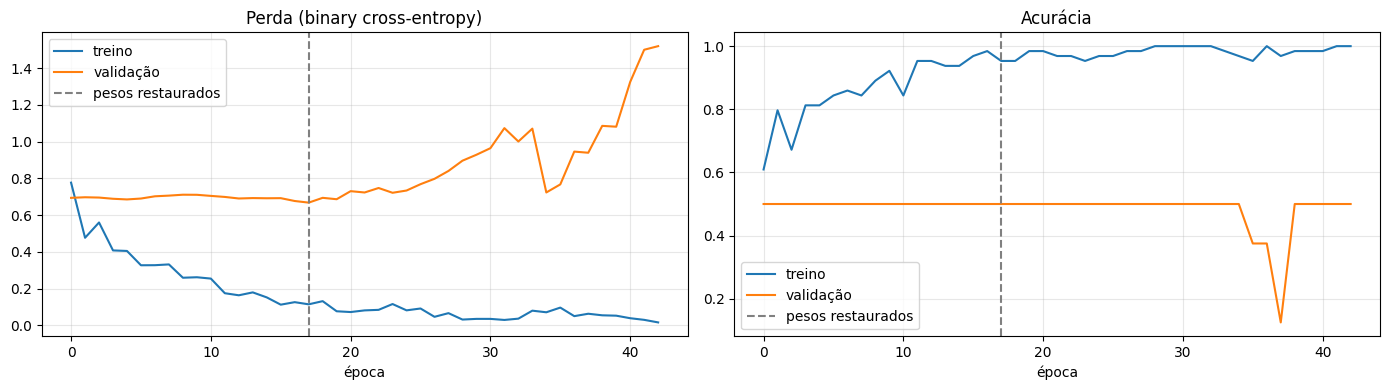

In [10]:
import matplotlib.pyplot as plt  # gráficos

fig, axes = plt.subplots(1, 2, figsize=(14, 4))  # perda e acurácia lado a lado
for ax, metric, title in ((axes[0], "loss", "Perda (binary cross-entropy)"), (axes[1], "accuracy", "Acurácia")):
    ax.plot(history_cnn.history[metric], label="treino")  # curva de treino
    ax.plot(history_cnn.history[f"val_{metric}"], label="validação")  # curva de validação
    ax.axvline(best_cnn_epoch - 1, color="gray", ls="--", label="pesos restaurados")  # época escolhida pelo early stopping
    ax.set_title(title)  # título
    ax.set_xlabel("época")  # eixo x
    ax.grid(alpha=0.3)  # grade leve
    ax.legend()  # legenda
plt.tight_layout()  # ajusta espaçamentos
plt.show()  # exibe

## 5. Avaliação comum: acurácia por imagem

Para cada imagem de validação e de teste, perguntamos aos três modelos: vaca ou cachorro?

- **A e B (YOLO):** a classe da detecção mais confiante entre `cow` e `dog`. Se nenhuma detecção dessas classes passar da confiança mínima, a resposta é "nenhuma" e conta como erro. No modelo B, mostramos também o que ele viu de mais confiante entre as 80 classes do COCO, para entender os erros (por exemplo, uma vaca vista como cavalo).
- **C (CNN):** `dog` se a probabilidade for maior que 0,5; senão, `cow`.

Os dois YOLO são carregados pelo `torch.hub` a partir da cópia local do YOLOv5.

In [11]:
def load_yolo(weights):
    # Carrega um modelo YOLOv5 a partir da pasta local (sem baixar código da internet)
    with run_in_yolo_dir():
        model = torch.hub.load(str(YOLO_DIR), "custom", path=str(weights), source="local", verbose=False)
    model.conf = CONF  # confiança mínima das detecções
    return model.to("mps" if DEVICE == "mps" else ("cpu" if DEVICE == "cpu" else "cuda:0"))  # mesmo dispositivo dos treinos


yolo_models = {"A": load_yolo(CUSTOM_WEIGHTS), "B": load_yolo(COCO_WEIGHTS)}  # customizado e pré-treinado
%matplotlib inline
# a linha acima restaura a exibição de gráficos: ao ser importado, o YOLOv5 troca o matplotlib para o modo 'Agg' (só arquivo)


def yolo_answer(model, image_path):
    # Responde 'cow', 'dog' ou 'nenhuma' para uma imagem; devolve também a detecção mais confiante de qualquer classe
    result = model(str(image_path), size=IMG_SIZE)  # leitura, pré-processamento, rede e NMS
    det = result.pandas().xyxy[0]  # tabela de detecções: classe, confiança, caixa
    ours = det[det["name"].isin(CLASSES)]  # só vaca e cachorro
    answer = ours.sort_values("confidence").iloc[-1]["name"] if len(ours) else "nenhuma"  # classe mais confiante
    top_any = f"{det.iloc[0]['name']} ({det.iloc[0]['confidence']:.2f})" if len(det) else "-"  # o que o modelo viu de mais confiante
    return answer, top_any


rows = []  # uma linha por imagem
cnn_prob = {s: cnn.predict(x, verbose=0).ravel() for s, (x, _) in {"val": (x_val, y_val), "test": (x_test, y_test)}.items()}  # probabilidades da CNN
for split in ("val", "test"):  # validação e teste
    for i, (path, truth) in enumerate(split_images(split)):  # cada imagem
        a, _ = yolo_answer(yolo_models["A"], path)  # resposta do YOLO customizado
        b, b_top = yolo_answer(yolo_models["B"], path)  # resposta do YOLO pré-treinado
        p = float(cnn_prob[split][i])  # probabilidade de 'dog' segundo a CNN
        rows.append({"divisão": split, "imagem": path.name, "verdade": truth, "A": a, "B": b,
                     "B: mais confiante (80 classes)": b_top, "C": "dog" if p > 0.5 else "cow", "C: P(dog)": round(p, 3)})
answers = pd.DataFrame(rows)  # tabela de respostas
answers[answers["divisão"] == "test"]  # exibe as respostas no teste

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


,divisão,imagem,verdade,A,B,B: mais confiante (80 classes),C,C: P(dog)
8,test,cow_037.jpg,cow,cow,cow,cow (0.92),cow,0.447
9,test,cow_038.jpg,cow,cow,cow,bird (0.80),dog,0.583
10,test,cow_039.jpg,cow,cow,cow,cow (0.77),dog,0.627
11,test,cow_040.jpg,cow,cow,cow,person (0.93),dog,0.558
12,test,dog_037.jpg,dog,dog,dog,dog (0.72),dog,0.696
13,test,dog_038.jpg,dog,dog,dog,dog (0.66),dog,0.534
14,test,dog_039.jpg,dog,cow,dog,dog (0.91),dog,0.592
15,test,dog_040.jpg,dog,dog,dog,dog (0.81),dog,0.621


In [12]:
accuracy = pd.DataFrame({split: {m: (answers.loc[answers["divisão"] == split, m] == answers.loc[answers["divisão"] == split, "verdade"]).mean()
                                 for m in ("A", "B", "C")} for split in ("val", "test")}).rename(columns={"val": "acurácia validação", "test": "acurácia teste"})  # acertos / total
accuracy  # exibe a acurácia de cada abordagem

,acurácia validação,acurácia teste
A,0.875,0.875
B,1.000,1.000
C,0.500,0.625


## 6. Avaliação de detecção: mAP dos dois YOLO

O mAP mede se o modelo encontra cada animal **e** posiciona a caixa corretamente (mAP@0.5 exige sobreposição de pelo menos 50% com a caixa rotulada; mAP@0.5:0.95 exige de 50% a 95%). A CNN não entra aqui, porque não produz caixas.

In [13]:
if str(YOLO_DIR) not in sys.path:  # permite importar os módulos do YOLOv5
    sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val  # módulo de validação do YOLOv5
%matplotlib inline
# restaura a exibição de gráficos depois de importar o YOLOv5


def map_metrics(weights, data_yaml, task, name):
    # mAP de um modelo YOLO num conjunto ('val' ou 'test'); verbose mostra as métricas por classe
    (mp, mr, map50, map5095, *_), _, _ = yolo_val.run(data=str(data_yaml), weights=str(weights), imgsz=IMG_SIZE, task=task,
                                                      device=DEVICE, project=str(YOLO_DIR / "runs" / "val"), name=name,
                                                      exist_ok=True, verbose=True, plots=True)
    return {"precision": mp, "recall": mr, "mAP@0.5": map50, "mAP@0.5:0.95": map5095}


detection = pd.DataFrame({
    f"{label} · {task}": map_metrics(weights, data_yaml, task, f"{key}_{task}")
    for key, label, weights, data_yaml in (("A", "A (customizado)", CUSTOM_WEIGHTS, DATA_YAML),
                                           ("B", "B (pré-treinado COCO)", COCO_WEIGHTS, COCO_DATA_YAML))
    for task in ("val", "test")}).T  # uma linha por modelo e conjunto
detection.round(3)  # exibe a tabela

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3it/s 0.8s
                   all          8         10      0.895      0.903      0.961       0.68
                   cow          8          6      0.828      0.807      0.927       0.71
                   dog          8          4      0.961          1      0.995       0.65
Speed: 3.1ms pre-process, 46.5ms inference, 1.5ms NMS per image at shape (32, 3, 640, 640)
Results saved to /content/yolov5/runs/val/A_val
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /con

,precision,recall,mAP@0.5,mAP@0.5:0.95
A (customizado) · val,0.895,0.903,0.961,0.680
A (customizado) · test,0.781,0.934,0.971,0.606
B (pré-treinado COCO) · val,0.978,0.917,0.984,0.841
B (pré-treinado COCO) · test,0.997,1.000,0.995,0.770


## 7. Tempo de inferência

Medimos o tempo **ponta a ponta** de cada modelo para responder sobre **uma imagem por vez**, do arquivo à resposta: leitura da imagem, pré-processamento, rede e pós-processamento (nos YOLO, a supressão de caixas sobrepostas). É o tempo que importa num sistema em produção, e é medido do mesmo jeito para os três, no mesmo dispositivo. Cada modelo faz uma passada de aquecimento antes (a primeira chamada inclui custos de inicialização), e reportamos a média das 8 imagens de teste.

Usamos o relógio do Python em volta da chamada inteira, que só termina quando a resposta já voltou da GPU. Não usamos o tempo interno que o YOLOv5 reporta pelo `torch.hub`: ele não espera a GPU terminar o cálculo e subestimaria a inferência. Por ser ponta a ponta, esses tempos não são comparáveis com o tempo só da rede medido pelo `detect.py` na Entrega 1.

In [14]:
def cnn_answer(image_path):
    # Responde 'cow' ou 'dog' para uma imagem, do arquivo à resposta (mesmo pré-processamento do treino)
    x = np.asarray(Image.open(image_path).convert("RGB").resize((CNN_SIZE, CNN_SIZE)), dtype="float32")[None]  # lote de 1 imagem
    p = float(keras.ops.convert_to_numpy(cnn(x, training=False))[0, 0])  # probabilidade de 'dog' (copiar para a CPU espera a GPU)
    return "dog" if p > 0.5 else "cow"


answer_fns = {"A": lambda p: yolo_answer(yolo_models["A"], p)[0],  # YOLO customizado
              "B": lambda p: yolo_answer(yolo_models["B"], p)[0],  # YOLO pré-treinado
              "C": cnn_answer}  # CNN
test_paths = [p for p, _ in split_images("test")]  # imagens de teste
infer_ms = {}  # ms por imagem, ponta a ponta, por abordagem
for key, answer in answer_fns.items():  # mesma medição para os três
    answer(test_paths[0])  # aquecimento
    times = []  # tempos de cada imagem
    for path in test_paths:  # uma imagem por vez
        t0 = time.perf_counter()  # início
        answer(path)  # do arquivo à resposta
        times.append((time.perf_counter() - t0) * 1000)  # ms
    infer_ms[key] = float(np.mean(times))  # média das 8 imagens
params = {"A": sum(p.numel() for p in yolo_models["A"].parameters()), "B": sum(p.numel() for p in yolo_models["B"].parameters()),
          "C": cnn.count_params()}  # tamanho de cada modelo
pd.DataFrame({"tempo por imagem, ponta a ponta (ms)": infer_ms, "parâmetros": params}).round(1)  # exibe

,"tempo por imagem, ponta a ponta (ms)",parâmetros
A,26.0,7015519
B,24.1,7225885
C,29.7,242017


## 8. Imagens de teste com as previsões

As detecções dos dois YOLO desenhadas sobre as 8 imagens de teste, e a resposta da CNN em cada uma.

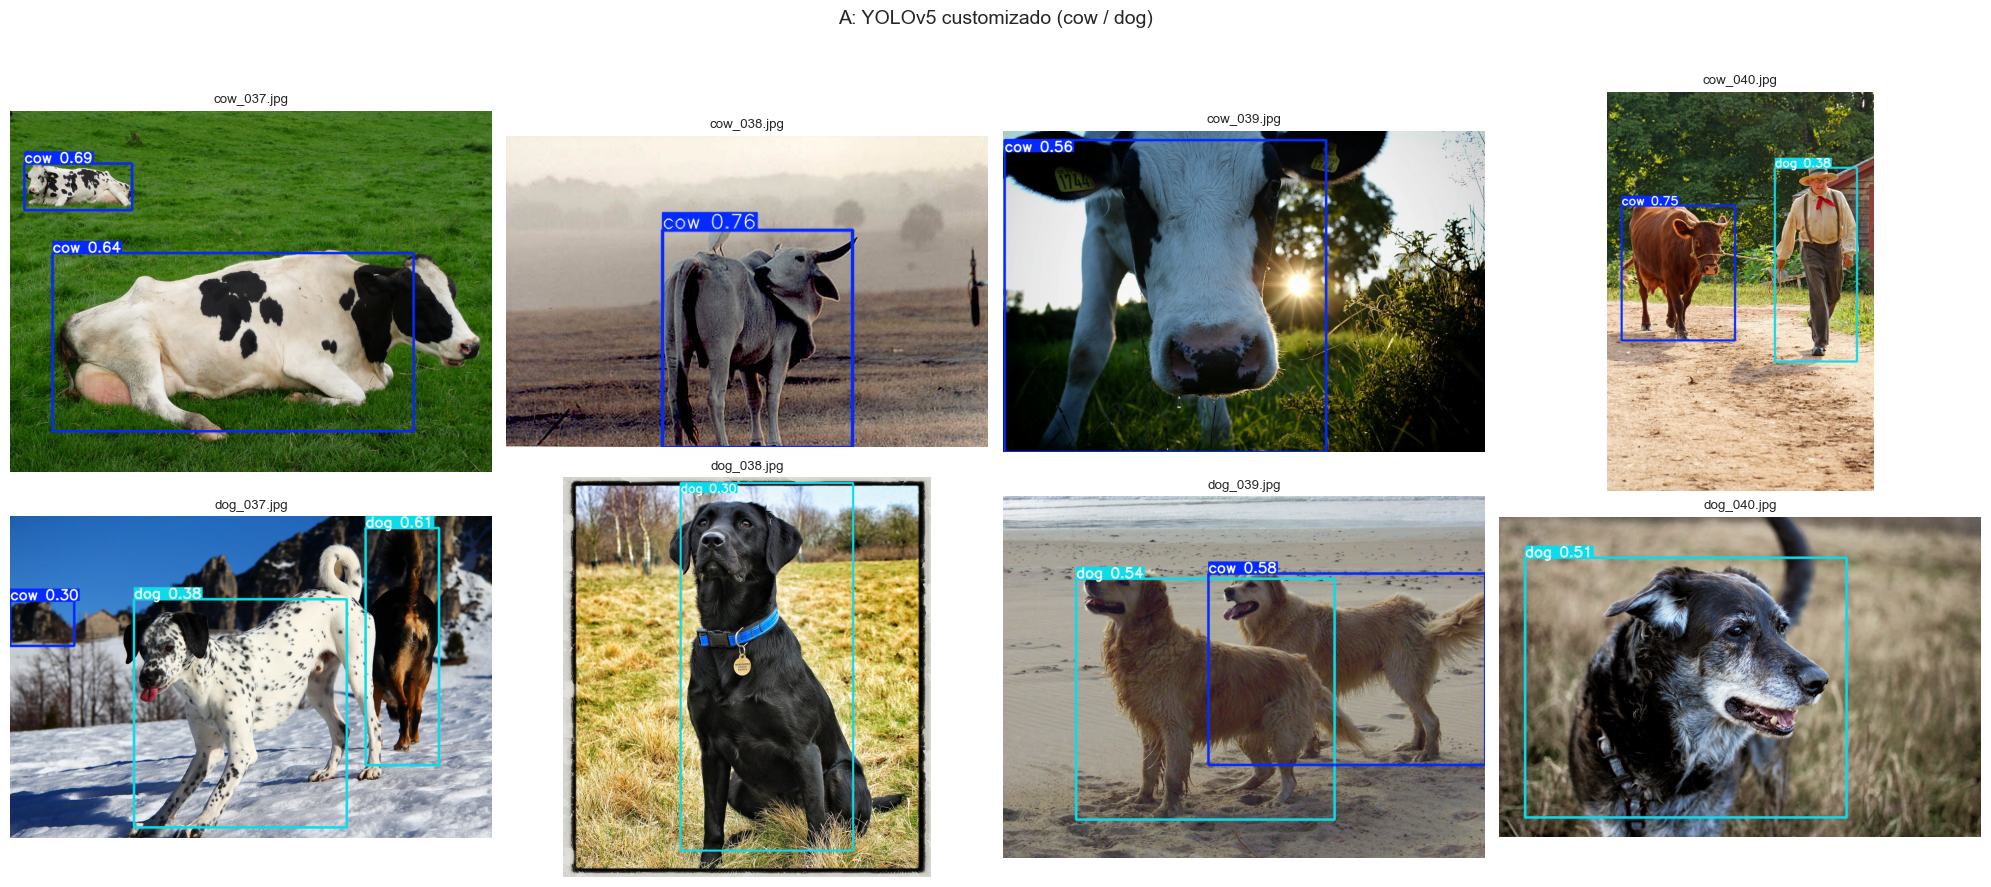

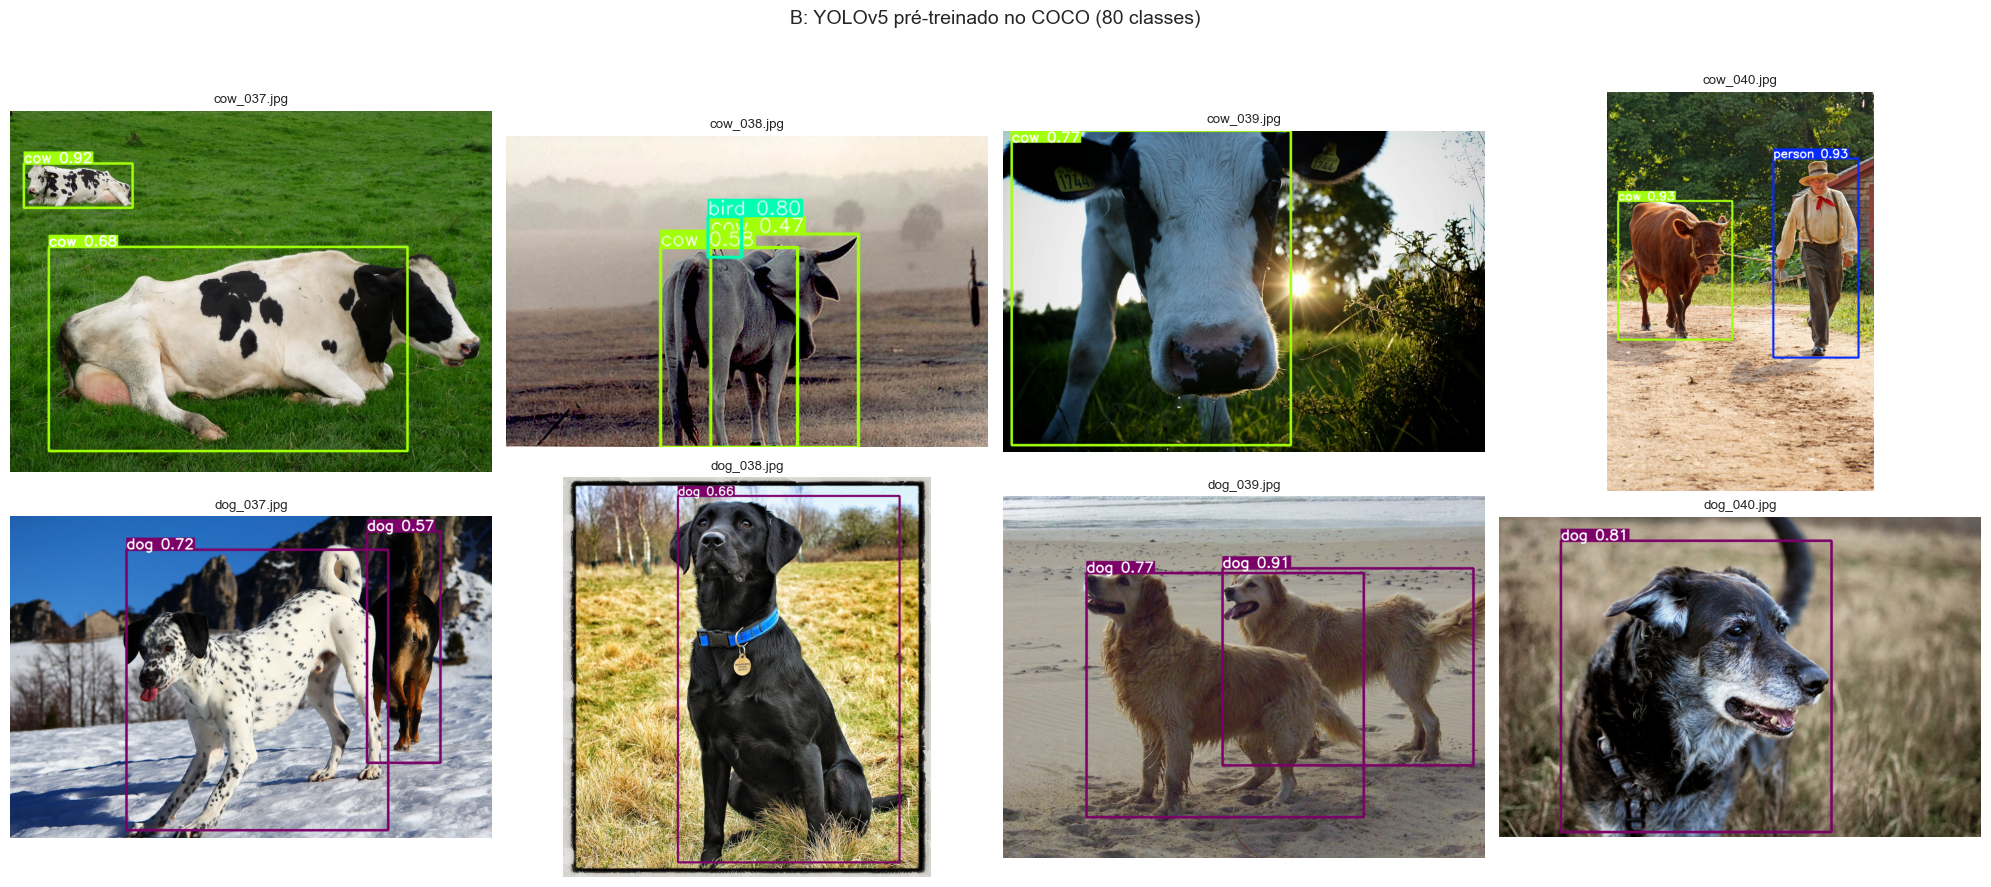

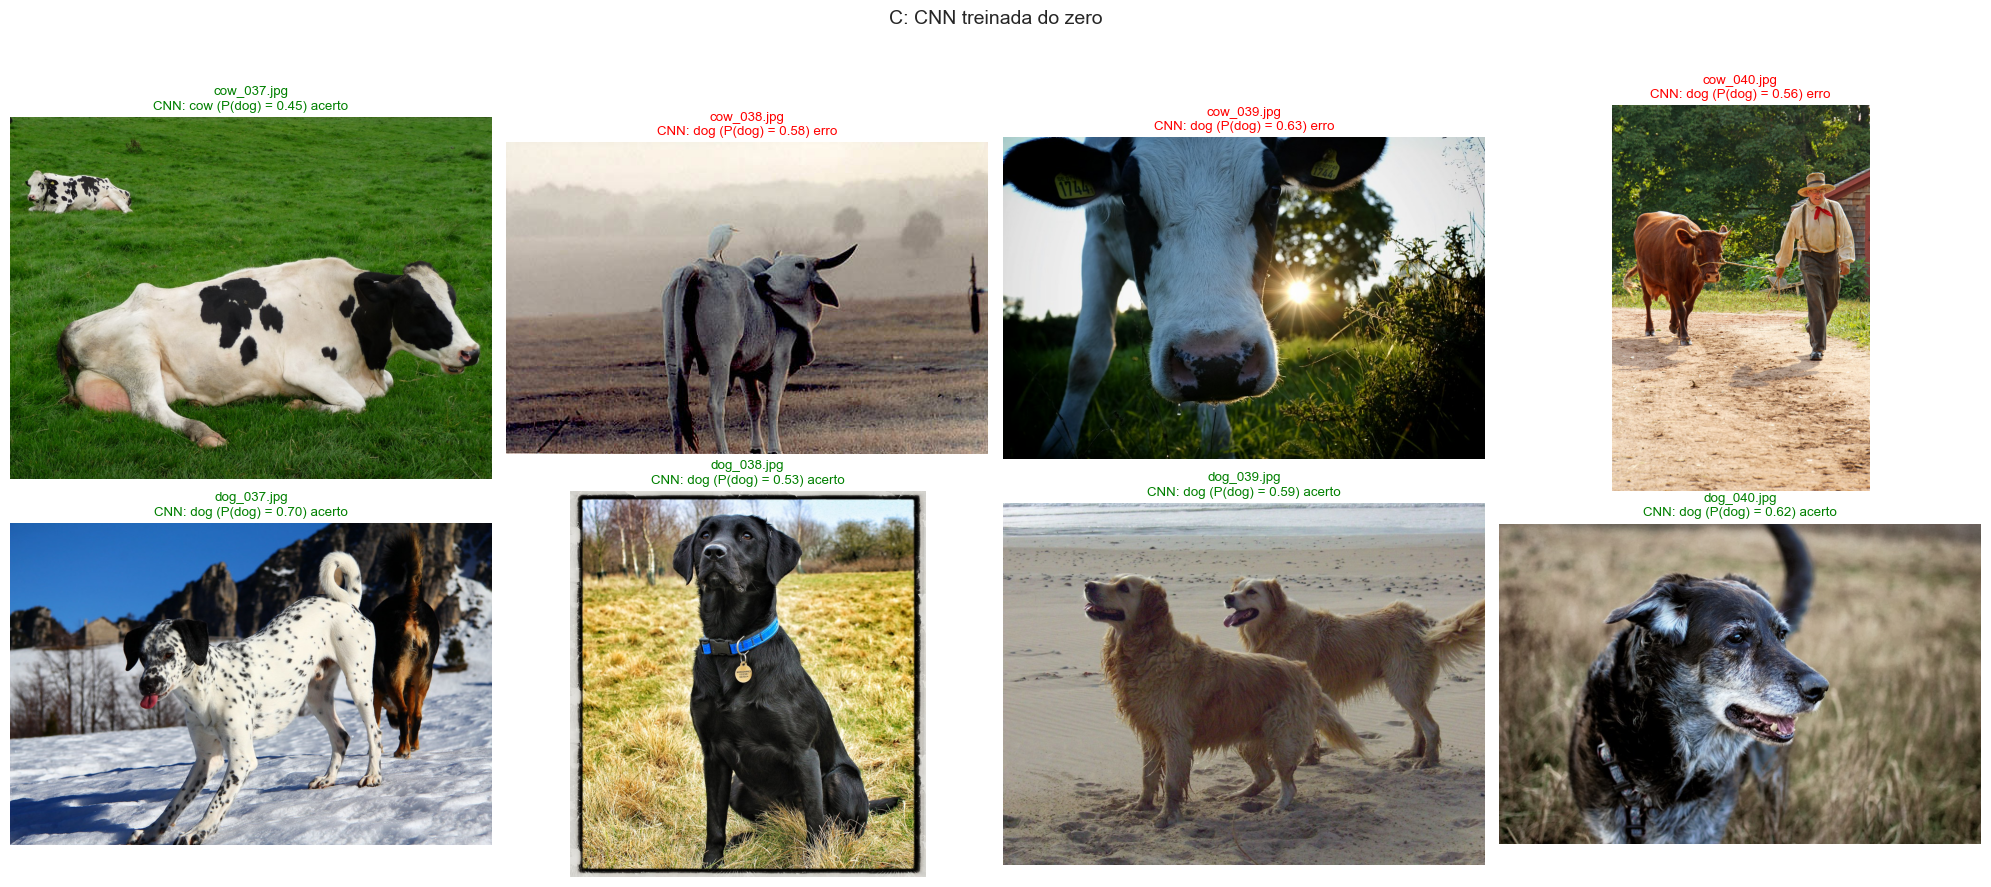

In [15]:
def show_yolo(key, title):
    # Desenha as detecções de um YOLO nas 8 imagens de teste
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))  # grade 2 x 4
    for ax, path in zip(axes.flat, test_paths):  # uma imagem por quadro
        result = yolo_models[key](str(path), size=IMG_SIZE)  # inferência
        ax.imshow(result.render()[0])  # imagem com as caixas desenhadas
        ax.set_title(path.name)  # nome do arquivo
        ax.axis("off")  # sem eixos
    fig.suptitle(title, fontsize=14)  # título
    plt.tight_layout(rect=(0, 0, 1, 0.96))  # ajusta espaçamentos
    plt.show()  # exibe


show_yolo("A", "A: YOLOv5 customizado (cow / dog)")
show_yolo("B", "B: YOLOv5 pré-treinado no COCO (80 classes)")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))  # respostas da CNN
for ax, (path, truth), p in zip(axes.flat, split_images("test"), cnn_prob["test"]):  # uma imagem por quadro
    guess = "dog" if p > 0.5 else "cow"  # resposta da CNN
    ax.imshow(Image.open(path))  # imagem original
    ax.set_title(f"{path.name}\nCNN: {guess} (P(dog) = {p:.2f}) {'acerto' if guess == truth else 'erro'}",
                 color="green" if guess == truth else "red")  # acerto em verde, erro em vermelho
    ax.axis("off")  # sem eixos
fig.suptitle("C: CNN treinada do zero", fontsize=14)  # título
plt.tight_layout(rect=(0, 0, 1, 0.96))  # ajusta espaçamentos
plt.show()  # exibe

## 9. Comparação crítica

A tabela reúne os números das seções anteriores. A facilidade de uso e de integração é avaliada abaixo dela, por critérios objetivos (o que cada abordagem exige para ser montada e usada).

In [16]:
summary = pd.DataFrame({
    "acurácia teste": accuracy["acurácia teste"],
    "acurácia validação": accuracy["acurácia validação"],
    "mAP@0.5 teste": {"A": detection.loc["A (customizado) · test", "mAP@0.5"], "B": detection.loc["B (pré-treinado COCO) · test", "mAP@0.5"], "C": float("nan")},
    "tempo de treino (min)": {k: v / 60 for k, v in TRAIN_TIME.items()},
    "tempo por imagem, ponta a ponta (ms)": infer_ms,
    "parâmetros (milhões)": {k: v / 1e6 for k, v in params.items()},
}).rename(index={"A": "A: YOLOv5 customizado", "B": "B: YOLOv5 pré-treinado", "C": "C: CNN do zero"})  # nomes legíveis
summary.round(3)  # exibe a tabela

,acurácia teste,acurácia validação,mAP@0.5 teste,tempo de treino (min),"tempo por imagem, ponta a ponta (ms)",parâmetros (milhões)
A: YOLOv5 customizado,0.875,0.875,0.971,3.681,26.015,7.016
B: YOLOv5 pré-treinado,1.000,1.000,0.995,0.000,24.137,7.226
C: CNN do zero,0.625,0.500,NaN,0.287,29.707,0.242


**Facilidade de uso e integração**

| Critério | A: YOLOv5 customizado | B: YOLOv5 pré-treinado | C: CNN do zero |
|---|---|---|---|
| Rotulação necessária | Caixas em cada animal (a etapa mais trabalhosa) | Nenhuma | Só a classe da imagem (o nome do arquivo basta) |
| Treino | Sim, com scripts prontos do YOLOv5 | Não | Sim, arquitetura e treino escritos por nós |
| Classes possíveis | Só as que rotulamos | Só as 80 do COCO | Só as que rotulamos |
| Saída | Caixa + classe de cada animal | Caixa + classe (entre 80) | Uma classe por imagem |
| Integração | Um arquivo `best.pt` e o pacote do YOLOv5 | Pesos públicos, uma linha de código | Um modelo Keras; pré-processamento é só redimensionar |
| Ajustes finos | Poucos: o YOLOv5 já traz hiperparâmetros e aumento de dados prontos | Nenhum possível sem treinar | Muitos: arquitetura, regularização e aumento de dados ficam por nossa conta |

## 10. Conclusões

Resultados desta execução (Google Colab, GPU Tesla T4). Os números citados vêm das tabelas e gráficos acima.

**Precisão**

- **O YOLO pré-treinado (B) foi o melhor, sem nenhum treino.** Acertou "vaca ou cachorro" nas 8 imagens de validação e nas 8 de teste, e teve o melhor mAP no teste: 0,995 de mAP@0.5 e 0,770 de mAP@0.5:0.95, contra 0,971 e 0,606 do nosso YOLO customizado (A). Ele também reconheceu corretamente o que não era vaca nem cachorro: a pessoa ao lado do boi (`cow_040`, 0,93) e a garça sobre o zebu (`cow_038`, 0,80).
- **O YOLO customizado (A) acertou 7 de 8 imagens no teste e 7 de 8 na validação.** O erro do teste foi `dog_039`: um dos golden retrievers foi detectado como vaca (0,58), com mais confiança que o outro, detectado como cachorro (0,54). Ele também viu um cachorro no homem de `cow_040` (0,38) e uma vaca numa casa ao fundo de `dog_037` (0,30); esses erros não mudam a resposta por imagem, mas aparecem na precisão das detecções no teste (0,781, contra 0,997 do modelo B). Os mesmos tipos de erro apareceram na Entrega 1.
- **A CNN treinada do zero (C) não aprendeu a separar as classes.** Acertou 5 de 8 no teste e 4 de 8 na validação, o nível de um chute. As curvas mostram que ela decorou o treino: a acurácia de treino chegou a 100%, enquanto a perda de validação ficou perto de 0,69 (o valor de um chute entre duas classes) e depois subiu, e a acurácia de validação ficou em 50% em quase todas as épocas. No teste, respondeu "cachorro" para 7 das 8 fotos, sempre com probabilidade entre 0,45 e 0,70, sem convicção. Com 64 imagens, uma rede que começa sem nenhum conhecimento prévio não tem exemplos suficientes para aprender o que diferencia os dois animais.

**Por que o modelo pré-treinado venceu o customizado**

Vaca e cachorro estão entre as 80 classes do COCO, que tem milhares de fotos rotuladas de cada uma. O modelo B usa esse conhecimento direto. O modelo A parte dos mesmos pesos, mas troca a camada final de 80 classes por uma de 2 e reaprende essa parte com só 64 imagens, das quais só 39 caixas são de cachorro; por isso ele é menos preciso justamente nos cachorros (mAP@0.5:0.95 de teste de 0,487 para cachorro e 0,725 para vaca, contra 0,775 e 0,766 do modelo B). Customizar compensa quando o que se quer detectar não existe no COCO.

**Tempo de treinamento e de inferência**

- **Treino/customização:** B não exige treino; C levou 0,3 min (43 épocas, interrompidas pelo *early stopping*); A levou 3,7 min (60 épocas). Nesta escala o tempo de treino não pesa: o custo real do modelo A é a rotulação das caixas, que levou mais tempo que todos os treinos somados.
- **Inferência, ponta a ponta:** os três ficaram na mesma faixa, de 24 a 30 ms por imagem (B 24,1, A 26,0 e C 29,7). A CNN tem 30 vezes menos parâmetros e ainda assim não foi mais rápida: com uma imagem por vez, o tempo é dominado pelos custos fixos de cada chamada (ler e redimensionar a imagem, preparar o lote, chamar o *framework*), não pelo cálculo da rede. Qualquer um dos três processaria na ordem de 30 a 40 imagens por segundo nesta GPU.

**Facilidade de uso e integração**

O modelo B é o mais fácil: pesos públicos, uma linha de código e nenhuma rotulação. O A exige a etapa mais trabalhosa do projeto, desenhar as caixas, mas o YOLOv5 traz treino, aumento de dados e avaliação prontos. O C é simples de rotular (a classe vem do nome do arquivo), mas tudo o mais fica por nossa conta, e com poucos dados ele não funciona.

**Limitações**

- Base pequena: 64 imagens de treino, 8 de validação e 8 de teste. Cada erro no teste muda a acurácia em 12,5 pontos; as diferenças entre abordagens indicam tendência, não precisão estatística.
- A acurácia por imagem simplifica a tarefa dos YOLO (que também localizam cada animal); por isso o mAP aparece separado.
- A vantagem do modelo B depende de as duas classes estarem no COCO; a comparação não diz nada sobre classes fora dele.
- O treino em GPU não é totalmente determinístico: os números dos modelos A e C variam um pouco entre execuções (o mesmo aconteceu na Entrega 1).
- Os tempos dependem do hardware (aqui, a GPU T4 do Colab).

**Recomendação para o cliente**

- **Para detectar vacas e cachorros, usar o YOLOv5 pré-treinado no COCO.** Foi o mais preciso, não exige rotulação nem treino e já distingue pessoas e outros animais, o que reduz alarmes falsos.
- **Customizar o YOLO (como na Entrega 1) quando o cliente precisar de algo que o COCO não tem**: raças específicas, sinais de doença, identificação de cada animal, equipamentos da fazenda. Nesse caso, investir em mais fotos por classe, com classes equilibradas.
- **Não usar uma CNN treinada do zero com esse volume de dados.** Para classificação, o caminho é partir de uma rede pré-treinada (*transfer learning*), como propõe o "Ir Além" desta fase.
